In [78]:
import snntorch.spikegen as spikegen
import torch
import math
import pandas as pd
import os
from scipy.stats import beta as beta_dist
import matplotlib.pyplot as plt

In [79]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

In [80]:
def load_all_data():
    """
    Load and combine all pre-split folds into one dataset
    
    The original dataset comes pre-split into 5 folds, but I combine them so I can split using
    groups over the patient id
    """
    all_folds = []
    for fold_num in range(5):
        fold_data = load_data(fold_num)
        all_folds.append(fold_data)
    
    combined = pd.concat(all_folds, ignore_index=True)
    print(f"Combined dataset shape: {combined.shape}")
    print(f"Total samples: {len(combined)}")
    
    return combined

In [81]:
def extract_and_normalize_top_features(df, top_features):
    """
        df: combined_data DataFrame
        top_features: list of top N features

        returns a normalized tensor
    """

    X = df[top_features].values
    X = torch.tensor(X, dtype=torch.float32)

    # Normalize features to range [0, 1]
    X_min = X.min(dim=0).values
    X_max = X.max(dim=0).values
    X_normalized = (X - X_min) / (X_max - X_min + 1e-8)  # avoid division by zero

    '''
    # safety cleanup
    X_norm = torch.nan_to_num(X_norm, nan=0.0, posinf=1.0, neginf=0.0)
    X_norm = X_norm.clamp(0, 1)
    '''
    return X_normalized

In [82]:
# beta distribution lets me control how strongly each feature value produces spikes, so depending on the certain features I may want to use 
# different encoding methods to generate spikes ???? 
# use beta distr. to introduce more preciseness along certain values (if they are very common)

def combined_beta_cdf(vsignal):

    v = float(vsignal)

    if v < 0.5:
        vnorm = 2 * v
        return beta_dist.cdf(vnorm, a=1.0, b=0.75)
    else:
        vnorm = 2 * v - 1
        return beta_dist.cdf(vnorm, a=0.75, b=1.0)

def rate_encoding_beta(X, timesteps=50, max_rate=100):
    
    batch_size, N_features = X.shape
    spike_train = torch.zeros(timesteps, batch_size, N_features)
    print(spike_train.shape)
    for b in range(batch_size):
        for f in range(N_features):
            Pfr = combined_beta_cdf(X[b,f])  # set prob of spiking for a value to just that value (Uniform distribution)
            #print(f'Actual value: {X[b,f]} and Pfr: {Pfr}')
            #spike_prob = (Pfr * max_rate) / timesteps
            #spike_prob = max(0.0, min(1.0, spike_prob))
            spike_train[:,b,f] = torch.bernoulli(Pfr * torch.ones(timesteps))

    return spike_train

In [83]:
def rate_encoding_Uniform(X, timesteps=50, max_rate=100):
    batch_size, N_features = X.shape
    spike_train = torch.zeros(timesteps, batch_size, N_features)
    for b in range(batch_size):
        for f in range(N_features):
            Pfr = X[b,f]    # the prob for value x of producing a spike is the value x (uniform distribution case)
            spike_train[:,b,f] = torch.bernoulli(Pfr * torch.ones(timesteps))

    print(spike_train)
    return spike_train

In [84]:
def plot_spike_train():
    spike_folder = './spiketrains'
    
    spikes_SBP = torch.load(os.path.join(spike_folder, "RE_spikegen_SBP"), weights_only=True)
    spikes_beta = torch.load(os.path.join(spike_folder, "RE_beta_SBP"), weights_only=True)
    spikes_uniform = torch.load(os.path.join(spike_folder, "RE_uniform_SBP"), weights_only=True)

    sample_std = spikes_SBP[:, 0, :]
    sample_beta = spikes_beta[:, 0, :]
    sample_uniform = spikes_uniform[:,0,:]

    def plot_raster(spikes, title):
        T, F = spikes.shape
        plt.figure(figsize=(10, 5))
        for f in range(F):
            t = torch.where(spikes[:, f] > 0)[0]
            plt.scatter(t, [f]*len(t), s=8)
        plt.title(title)
        plt.xlabel("Time")
        plt.ylabel("Neuron")
        plt.show()

    plot_raster(sample_std, "Standard Rate Encoding using spikegen")
    plot_raster(sample_uniform, "Uniform self implemented")
    plot_raster(sample_beta, "Beta Encoding self implemented")


Combined dataset shape: (3063, 222)
Total samples: 3063
tensor([[[1., 1., 0.,  ..., 0., 0., 0.],
         [1., 0., 0.,  ..., 1., 0., 0.],
         [0., 0., 1.,  ..., 1., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 1., 0., 1.],
         [0., 0., 1.,  ..., 1., 1., 1.],
         [1., 0., 1.,  ..., 0., 0., 1.]],

        [[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 1., 0., 0.],
         [1., 0., 1.,  ..., 0., 1., 0.],
         ...,
         [1., 0., 0.,  ..., 0., 0., 1.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 1., 0., 0.]],

        [[1., 0., 0.,  ..., 1., 0., 0.],
         [0., 0., 1.,  ..., 1., 0., 0.],
         [0., 1., 0.,  ..., 1., 1., 0.],
         ...,
         [0., 0., 0.,  ..., 1., 0., 0.],
         [1., 0., 0.,  ..., 1., 0., 1.],
         [0., 0., 0.,  ..., 1., 0., 0.]],

        ...,

        [[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 1., 0.,  ..., 0., 0., 0.],
         [1., 0., 1.,  ..., 0., 1., 1.],
         ...,
       

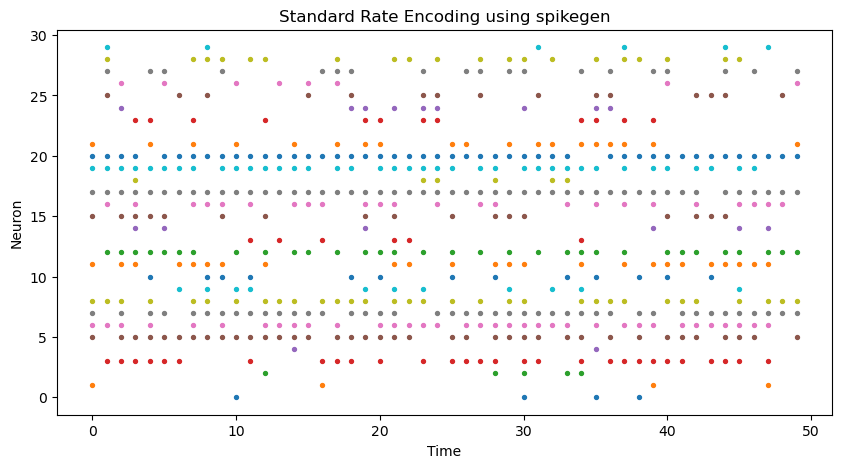

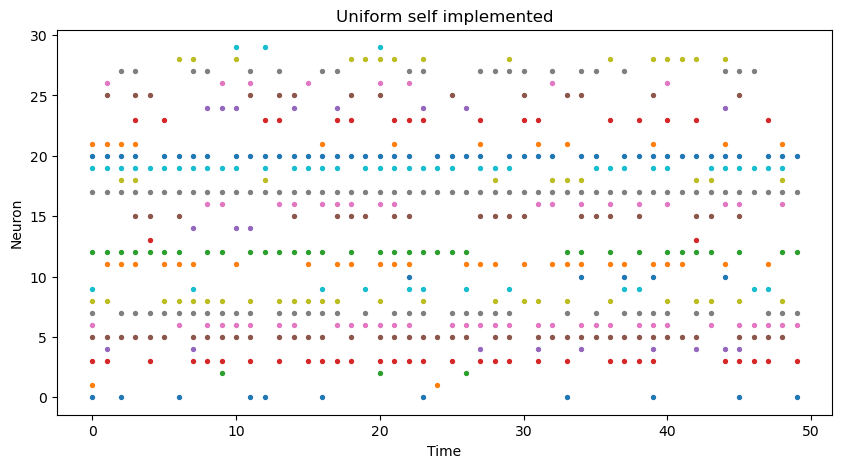

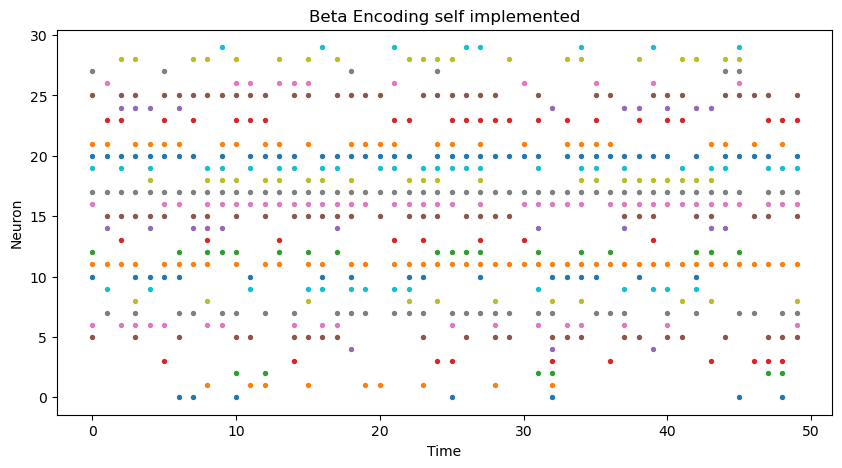

In [ ]:
combined_data = load_all_data()
timesteps = 50
spike_folder = 'spiketrains'
os.makedirs(spike_folder, exist_ok=True)

'''
top_N_features_SBP = [
    'TNegSteepest_norm',
    'ppg_histogram_down_2',
    'vpg_max_0',
    'DWdivSW50',
    'ppg_min_0',
    'apg_b',
    'apg_min_0',
    'p2p_0',
    'SWaddDW50',
    'SW75_norm',
    'vpg_histogram_down_1',
    'apg_histogram_up_0',
    'S3_norm',
    'T_e_norm',
    'apg_histogram_down_2',
    'T_peak_e',
    'DW50_norm',
    'ppg4_histogram_down_5',
    'AUCsys',
    'apg_histogram_up_4',
    'ppg_b',
    'S2',
    'ppg4_histogram_down_2',
    'ppg3_histogram_down_9',
    'apg_max_0',
    'ppg_fft_peaks_heights_0',
    'vpg_histogram_up_2',
    'TSystoDiaRise_norm',
    'T_c',
    'hr_0'
]

top_N_features_DBP =  [
    'T_peak_a',
    'ppg4_histogram_down_2',
    'T_peak_e_norm',
    'ppg4_histogram_down_5',
    'vpg_histogram_down_8',
    'vpg_histogram_down_0',
    'ppg3_histogram_down_5',
    'DWdivSW75',
    'SW25',
    'T_peak_e',
    'vpg_histogram_down_7',
    'ppg4_histogram_up_2',
    'T_peak_c',
    'SW50_norm',
    'ppg4_histogram_down_0',
    'TNegSteepest',
    'apg_histogram_up_4',
    'ppg4_histogram_down_1',
    'AUCdia',
    'usdc_3',
    'ppg_e',
    'apg_histogram_up_3',
    'TSystoDiaRise_norm',
    'ppg3_max_0',
    'ppg4_histogram_up_0',
    'SW50',
    'ppg_histogram_down_5',
    'T_peak_a_norm',
    'SQI_kurtosis',
    'S4'
]
'''


top_N_features_SBP = [
    'AUCsys_norm',
    'TdiaToEnd',
    'AUCdia_norm',
    'T_peak_e_norm',
    'ppg_histogram_down_2',
    'T_peak_a',
    'SteepDiaRise',
    'vpg_max_neighbor_mean_0',
    'TNegSteepest_norm',
    'ppg4_max_0',
    'TSystoDiaRise',
    'usdc_2',
    'ppg3_histogram_down_8',
    'T_peak_e',
    'vpg_histogram_down_0',
    'apg_histogram_down_3',
    'TNegSteepest',
    'ratio_apg_b',
    'TdiaRise',
    'ppg4_min_0',
    'ppg_max_neighbor_mean_0',
    'Td',
    'dsdc_12',
    'T_b',
    'dsdc_18',
    'Tc',
    'S4_norm',
    'dsdc_2',
    'sdoo',
    'ppg3_histogram_down_7'
]

top_N_features_DBP = [
    'dsdc_8',
    'TdiaToEnd',
    'ppg_histogram_down_4',
    'Td',
    'S4',
    'vpg_histogram_down_0',
    'vpg_max_neighbor_mean_0',
    'T_peak_e',
    'ppg4_histogram_down_3',
    'T_peak_a',
    'dsdc_9',
    'ppg3_histogram_down_8',
    'SteepDiaRise',
    'vpg_histogram_down_4',
    'S3_norm',
    'S4_norm',
    'ratio_apg_b',
    'TNegSteepest',
    'ppg_histogram_down_5',
    'ppg_histogram_down_1',
    'ratio_apg_d',
    'ppg4_histogram_down_6',
    'T_b',
    'ppg_histogram_down_3',
    'T_peak_e_norm',
    'ppg_histogram_down_2',
    'T_d_norm',
    'TSystoDiaRise',
    'apg_histogram_down_5',
    'TdiaRise'
]


X_SBP = extract_and_normalize_top_features(combined_data, top_N_features_SBP)
X_DBP = extract_and_normalize_top_features(combined_data, top_N_features_DBP)
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")


Y_SBP = torch.tensor(combined_data['SP'].values,dtype=torch.float32)
# 1. Use spikegen function imported from snnTorch (what the initial SNN uses), this uses the mean of a binomial distribution 
spikes_SBP = spikegen.rate(
    X_SBP,
    num_steps=timesteps,
).to(device)
# output: [timesteps, input size, N_features]
torch.save(spikes_SBP, os.path.join(spike_folder, 'RE_spikegen_SBP'))

Y_DBP = torch.tensor(combined_data['DP'].values, dtype=torch.float32)
spikes_DBP = spikegen.rate(
    X_DBP,
    num_steps=timesteps
).to(device)
torch.save(spikes_DBP,os.path.join(spike_folder, 'RE_spikegen_DBP'))


# 2. Use self made rate encoding using uniform distribution following the paper 'Evaluation of Encoding Schemes on Ubiquitous Sensor Signal for Spiking Neural Network'
spikes_SBP_Uniform = rate_encoding_Uniform(X_SBP,timesteps=timesteps)
torch.save(spikes_SBP_Uniform, os.path.join(spike_folder, 'RE_uniform_SBP'))

spikes_DBP_Uniform = rate_encoding_Uniform(X_DBP, timesteps=timesteps)
torch.save(spikes_DBP_Uniform, os.path.join(spike_folder, 'RE_uniform_DBP'))


# 3. Use Beta encoding for spikes
spikes_SBP_Beta = rate_encoding_beta(X_SBP,timesteps=timesteps)
torch.save(spikes_SBP_Beta, os.path.join(spike_folder, 'RE_beta_SBP'))

spikes_DBP_Beta = rate_encoding_beta(X_DBP, timesteps=timesteps)
torch.save(spikes_DBP_Beta, os.path.join(spike_folder, 'RE_beta_DBP'))


plot_spike_train()
